# 03 - Models, tuning and selection (validation data only)
Blueprint P2.2-P2.4. Every number in this notebook comes from the validation split; the test split and SmartBugs were not used.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import Image, display, Markdown
pd.set_option('display.max_colwidth', 120)
T = ROOT / 'reports' / 'tables'
F = ROOT / 'reports' / 'figures'

In [2]:
pd.read_csv(T / 'validation_grid.csv')

,family,params,val_macro_pr_auc,fit_seconds,source,val_pr_auc_0,val_pr_auc_1,val_pr_auc_2,val_pr_auc_3,val_pr_auc_4,val_pr_auc_5,val_pr_auc_6
0,prior,{},0.20664,0.0,fitted,0.14008,0.19992,0.03781,0.04693,0.32780,0.29480,0.39912
1,logreg,"{""C"": 0.25}",0.74430,72.0,"first full run log (08 Nov), not re-fitted",NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,logreg,"{""C"": 1.0}",0.78740,94.0,"first full run log (08 Nov), not re-fitted",NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,logreg,"{""C"": 4.0}",0.81204,141.0,model saved by first full run (08 Nov),0.73070,0.84261,0.77842,0.62857,0.87632,0.87666,0.95101
4,tree,"{""max_depth"": 16, ""min_samples_leaf"": 5}",0.47500,1180.0,"first full run log (08 Nov), not re-fitted",NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,tree,"{""max_depth"": 16, ""min_samples_leaf"": 20}",0.48980,1026.0,"first full run log (08 Nov), not re-fitted",NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,tree,"{""max_depth"": 32, ""min_samples_leaf"": 5}",0.48410,1595.0,"first full run log (08 Nov), not re-fitted",NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,tree,"{""max_depth"": 32, ""min_samples_leaf"": 20}",0.51433,1212.0,model saved by first full run (08 Nov),0.38371,0.49946,0.34280,0.23435,0.65919,0.68210,0.79867
8,forest,"{""n_estimators"": 200, ""max_depth"": null, ""min_samples_leaf"": 1}",0.77134,5378.6,fitted,0.69656,0.78558,0.76344,0.49105,0.84988,0.87468,0.93819
9,forest,"{""n_estimators"": 200, ""max_depth"": 40, ""min_samples_leaf"": 2}",0.76440,1858.5,fitted,0.67699,0.77956,0.75887,0.48026,0.84786,0.87146,0.93582


In [3]:
pd.read_csv(T / 'model_selection_val.csv')

,model,params,val_macro_pr_auc,val_macro_f2,val_macro_f1,ece_before,ece_after,calibrated,fit_seconds,size_mb,primary
0,mlp,"{""input"": ""tfidf"", ""seed"": 44}",0.84607,0.81559,0.74823,0.04746,0.04746,False,8079.1,18.28,True
1,logreg,"{""C"": 4.0}",0.81204,0.81157,0.71876,0.07337,0.01257,True,141.0,0.94,False
2,forest,"{""n_estimators"": 200, ""max_depth"": null, ""min_samples_leaf"": 1}",0.77134,0.76194,0.66331,0.05620,0.01188,True,5378.6,215.14,False
3,knn,"{""k"": 15}",0.61521,0.65134,0.55425,0.04116,0.04116,False,0.5,87.24,False
4,tree,"{""max_depth"": 32, ""min_samples_leaf"": 20}",0.51433,0.64440,0.49558,0.15279,0.03166,True,1212.0,0.30,False
5,prior,{},0.20664,0.50289,0.32302,0.02131,0.02131,False,0.0,0.00,False


In [4]:
pd.read_csv(T / 'thresholds_val.csv')

,model,class,threshold,fbeta,precision,recall,guard_met
0,prior,access-control,0.15042,0.44887,0.14008,1.00000,False
1,prior,arithmetic,0.18805,0.55543,0.19992,1.00000,False
2,prior,bad-randomness,0.03803,0.16422,0.03781,1.00000,False
3,prior,locked-ether,0.04998,0.19757,0.04693,1.00000,False
4,prior,other,0.33948,0.70916,0.32780,1.00000,True
5,prior,reentrancy,0.28502,0.67640,0.29480,1.00000,True
6,prior,unchecked-calls,0.50136,0.76858,0.39912,1.00000,True
7,logreg,access-control,0.09975,0.73200,0.43261,0.88515,True
8,logreg,arithmetic,0.15194,0.82879,0.59594,0.91850,True
9,logreg,bad-randomness,0.19361,0.84940,0.73589,0.88347,True


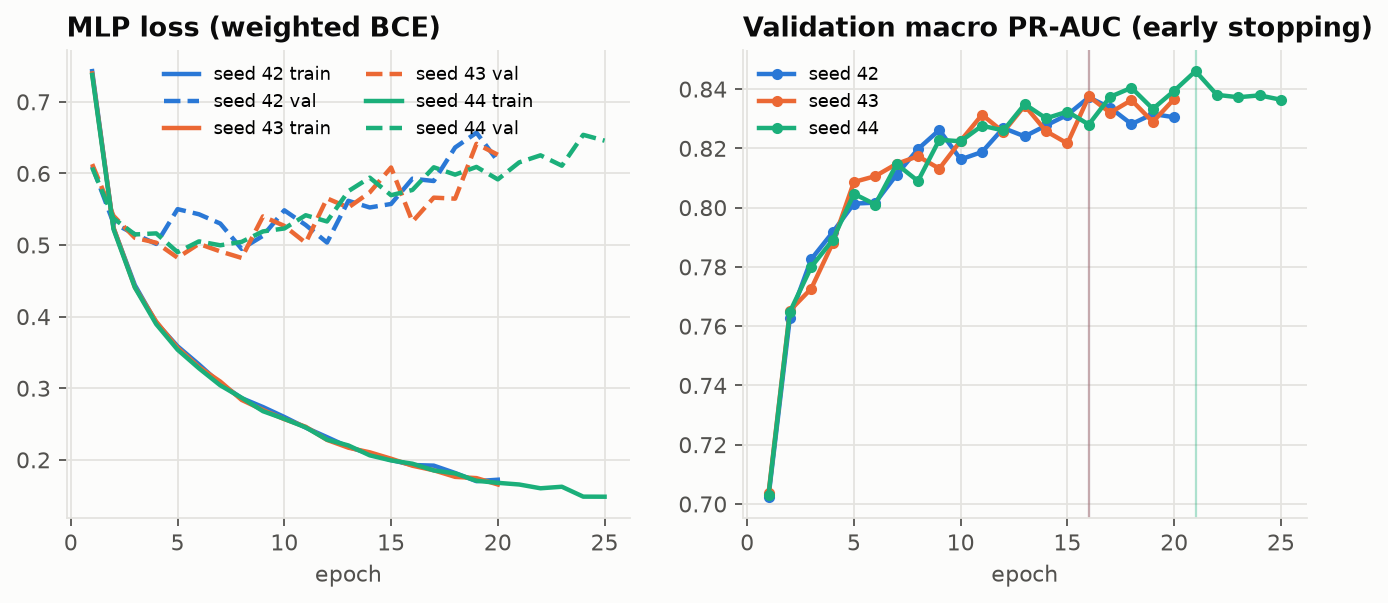

,seed,val_macro_pr_auc,best_epoch,epochs_run
0,42,0.83721,16,20
1,43,0.83754,16,20
2,44,0.84607,21,25


In [5]:
display(Image(F / 'mlp_learning_curves.png'))
pd.read_csv(T / 'mlp_seeds.csv')

In [6]:
json.load(open(ROOT / 'models/thresholds.json'))['primary']

'mlp'